# 本実験：Qwen → Mistral の逐次再測定（生成・CPU翻訳一式）

- **200問×3反復×日英2言語 = 1,200生成／モデル。** Qwen終了後にMistralへ移ります。GPU生成から翻訳まで同一Notebookで再測定します。
- Argosの段落翻訳結果キャッシュを**毎回の測定直前**に消去します。GPU生成・翻訳器の推論パラメータは元のNotebookから変更しません。
- 一時的なGPU生成・CPU翻訳の計測エラーは**最大3回**（最初の1回+再試行2回）挑戦。失敗は `errors.jsonl` のみへ記録。意図的なトークン上限除外は通常ログへ記録して再試行しません。
- Google Driveに1件ずつ保存。切断時は**同じRUN_LABELで「すべてのセルを実行」**すると成功・正当な除外済みの試行をスキップします。
- 実行完了の確認は最終セルの `run_status.json` を使用。**`completed_all_attempts` のみが全予定キーの完了を表します**（全件が品質基準を満たした意味ではありません）。
- データ保存先は旧Qwen・MistralおよびLLM-jp・Ayaのフォルダと分離しています。GPU L4で実行してください。
- Colab ProでもPCシャットダウン後の実行継続は保証されません。


In [ ]:
# Argos Translateをimportする前に必ず設定（CPU翻訳のみ）
import os
os.environ["ARGOS_DEVICE_TYPE"] = "cpu"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print("Argos device policy: CPU")

Argos device policy: CPU


In [ ]:
%pip -q install "transformers>=4.44,<5" "accelerate>=0.29" datasets sentencepiece sacremoses safetensors "codecarbon==3.3.2" nvidia-ml-py psutil argostranslate bitsandbytes "sympy==1.14.0"

In [ ]:

# ==========================================
# ライブラリ・GPU動作確認
# ==========================================

from importlib.metadata import version

import torch
import transformers
import huggingface_hub
import argostranslate.package
import argostranslate.translate

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
)

print("=== ライブラリ確認 ===")

packages = [
    "torch",
    "transformers",
    "huggingface-hub",
    "argostranslate",
    "codecarbon",
    "nvidia-ml-py",
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except Exception as e:
        print(f"⚠️ {package}: {e}")

print("\n=== GPU確認 ===")

if torch.cuda.is_available():
    print("✅ CUDA利用可能")
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPUメモリ:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GiB"
    )
else:
    print("❌ CUDAが利用できません")

print("\n✅ ライブラリの基本インポート確認完了")


=== ライブラリ確認 ===
torch: 2.11.0+cu130
transformers: 4.57.6
huggingface-hub: 0.36.2
argostranslate: 1.11.0
codecarbon: 3.3.2
nvidia-ml-py: 13.615.71

=== GPU確認 ===
✅ CUDA利用可能
GPU: NVIDIA L4
GPUメモリ: 22.03 GiB

✅ ライブラリの基本インポート確認完了


In [ ]:
# Qwen・Mistralは公開モデルのためAyaのゲートモデル用認証は不要。
# LLM-jp・Aya用Notebookからの流用時に、Aya専用認証・モデル事前DLを行わない。
print("Qwen/Mistral: gated HF authorization step skipped")


Qwen/Mistral: gated HF authorization step skipped


In [ ]:

import os

# ==========================================
# 1. 環境設定
# ==========================================

# Argos TranslateがGPUを使わないよう、import前に設定
os.environ["ARGOS_DEVICE_TYPE"] = "cpu"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ==========================================
# 2. 実験モード
# ==========================================

MODE = "full"  # 試運転時は "smoke"
RUN_LABEL = f"revision_v3_{MODE}_qwen_mistral_no_argos_cache_retry"

if MODE not in ("smoke", "full"):
    raise ValueError(
        f"無効なMODEです: '{MODE}'。"
        "'smoke' または 'full' を指定してください。"
    )

# ==========================================
# 3. LLMモデル一覧
# ==========================================

LLM_MODELS = {
    "qwen": {
        "id": "Qwen/Qwen2.5-7B-Instruct",
        "trust_remote_code": False,
    },
    "mistral": {
        "id": "mistralai/Mistral-7B-Instruct-v0.3",
        "trust_remote_code": False,
    },
    "llm_jp": {
        "id": "llm-jp/llm-jp-3-7.2b-instruct",
        "trust_remote_code": False,
    },
    "aya": {
    "id": "CohereLabs/aya-expanse-8b",
    "trust_remote_code": False,
},
}

# ==========================================
# 4. 翻訳モデル一覧
# ==========================================

TRANSLATORS = {
    "argos": "en→ja (Argos Translate)",
    "fugumt": "staka/fugumt-en-ja",
    "nllb": "facebook/nllb-200-distilled-600M",
}

# ==========================================
# 5. 実験規模
# ==========================================

NUM_SAMPLES = 5 if MODE == "smoke" else 200

REPEAT_COUNT = 1 if MODE == "smoke" else 3

# 1つのL4ランタイムで、Qwen完了後にMistralを逐次実行
ACTIVE_MODELS = ["qwen", "mistral"]

ACTIVE_TRANSLATORS = list(TRANSLATORS)

# ==========================================
# 6. データセット設定
# ==========================================

DATASET_ID = "kunishou/databricks-dolly-15k-ja"
DATASET_SEED = 42
ORDER_SEED = 2026

# ==========================================
# 7. 推論・計測設定
# ==========================================

MAX_NEW_TOKENS = 512
MAX_INPUT_TOKENS = 2048
BATCH_SIZE = 1

MODEL_DTYPE = "float16"
GPU_IDLE_SECONDS = 3

# ==========================================
# 8. 設定チェック
# ==========================================

for key in ACTIVE_MODELS:
    if key not in LLM_MODELS:
        raise ValueError(f"未登録のLLMモデル: {key}")

for key in ACTIVE_TRANSLATORS:
    if key not in TRANSLATORS:
        raise ValueError(f"未登録の翻訳器: {key}")

print("mode:", MODE)
print("run_label:", RUN_LABEL)
print("models:", ACTIVE_MODELS)
print("samples:", NUM_SAMPLES)
print("repeats:", REPEAT_COUNT)
print("translators:", ACTIVE_TRANSLATORS)
print(
    "planned_generations:",
    NUM_SAMPLES * REPEAT_COUNT * len(ACTIVE_MODELS) * 2
)

# モデル2つまとめてRUN_DIRを分離保存。model_keyでファイル内区別できます。
# 同じ条件・RUN_LABELでは既存行をスキップして再開します。
TRANSLATION_CACHE_POLICY = "argos_cached_paragraphs_cleared_before_each_measurement"
# 測定に失敗した場合の最大試行回数（初回を含む）。待機は測定区間外。
MAX_MEASUREMENT_ATTEMPTS = 3
RETRY_DELAY_SECONDS = 3


mode: full
run_label: revision_v3_full_qwen_mistral_no_argos_cache_retry
models: ['qwen', 'mistral']
samples: 200
repeats: 3
translators: ['argos', 'fugumt', 'nllb']
planned_generations: 2400


In [ ]:
import sys, json, hashlib, re, platform, subprocess, time, gc, random
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import transformers
import codecarbon
import pynvml
from google.colab import drive

drive.mount("/content/drive")
if not torch.cuda.is_available():
    raise RuntimeError("Colabのランタイム設定でGPUを選択してください")

pynvml.nvmlInit()
GPU_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
GPU_NAME = pynvml.nvmlDeviceGetName(GPU_HANDLE)
if isinstance(GPU_NAME, bytes):
    GPU_NAME = GPU_NAME.decode()
GPU_TAG = re.sub(r"[^a-zA-Z0-9_-]+", "_", GPU_NAME).strip("_")
try:
    _ = pynvml.nvmlDeviceGetTotalEnergyConsumption(GPU_HANDLE)
except pynvml.NVMLError as exc:
    # 1. API自体がハードウェア/ドライバに未対応
    if exc.value == pynvml.NVML_ERROR_NOT_SUPPORTED:
        raise RuntimeError(
            f"【未対応GPU】{GPU_NAME} は累積エネルギー（TotalEnergyConsumption）の取得をサポートしていません。\n"
            "→ 対策: A100/H100/L4 などの対応GPUを選択するか、定期サンプリング方式（nvmlDeviceGetPowerUsage）や "
            "CodeCarbon単体での測定に切り替えてください。"
        ) from exc

    # 2. 権限不足（Colabコンテナやクラウドの制約）
    elif exc.value == pynvml.NVML_ERROR_NO_PERMISSION:
        raise RuntimeError(
            f"【権限エラー】{GPU_NAME} の電力情報へのアクセス権限がありません。\n"
            "→ 対策: root/管理者権限で実行するか、クラウド環境のセキュリティ設定を確認してください。"
        ) from exc

    # 3. GPUがデタッチされた・応答しないなど致命的なエラー
    elif exc.value in (pynvml.NVML_ERROR_GPU_IS_LOST, pynvml.NVML_ERROR_UNKNOWN):
        raise RuntimeError(
            f"【ハードウェア異常】GPUとの通信に失敗しました (Error Code: {exc.value})。\n"
            "→ 対策: ランタイムを再起動してください。"
        ) from exc

    # 4. その他のNVMLエラー
    else:
        raise RuntimeError(
            f"【NVMLエラー】予期せぬエラーが発生しました: {exc} (Code: {exc.value})"
        ) from exc

CONFIG = dict(
    translation_cache_policy=TRANSLATION_CACHE_POLICY,
    max_measurement_attempts=MAX_MEASUREMENT_ATTEMPTS,
    retry_delay_seconds=RETRY_DELAY_SECONDS,
    mode=MODE, run_label=RUN_LABEL, dataset=DATASET_ID, dataset_seed=DATASET_SEED,
    order_seed=ORDER_SEED, num_samples=NUM_SAMPLES, repeat_count=REPEAT_COUNT,
    models={k: LLM_MODELS[k] for k in ACTIVE_MODELS},
    translators={k: TRANSLATORS[k] for k in ACTIVE_TRANSLATORS},
    max_new_tokens=MAX_NEW_TOKENS, max_input_tokens=MAX_INPUT_TOKENS,
    batch_size=BATCH_SIZE, dtype=MODEL_DTYPE, gpu_name=GPU_NAME,
    generator="greedy_do_sample_false", cpu_energy="CodeCarbon_estimate_process_mode",
    gpu_energy="NVML_total_energy_device_level",
)
CONFIG_HASH = hashlib.sha256(json.dumps(CONFIG, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:12]
ROOT = Path("/content/drive/MyDrive/LLM_Energy_Experiment_v2")
RUN_DIR = ROOT / RUN_LABEL / MODE / GPU_TAG / CONFIG_HASH
RUN_DIR.mkdir(parents=True, exist_ok=True)
GEN_LOG = RUN_DIR / "generations.jsonl"
TRANS_LOG = RUN_DIR / "translations.jsonl"
ERROR_LOG = RUN_DIR / "errors.jsonl"
META_FILE = RUN_DIR / "metadata.json"

# 同じ出力場所で異なる条件を混在させない
if META_FILE.exists():
    saved = json.loads(META_FILE.read_text(encoding="utf-8"))
    if saved.get("config") != CONFIG:
        raise RuntimeError("既存データと設定が異なります。RUN_LABELを変更してください")
else:
    try:
        cpu_lines = Path("/proc/cpuinfo").read_text().splitlines()
        cpu_name = next((line.split(":",1)[1].strip() for line in cpu_lines if line.startswith("model name")), "unknown")
    except Exception:
        cpu_name = "unknown"
    meta = dict(config=CONFIG, created_utc=datetime.now(timezone.utc).isoformat(),
        environment=dict(gpu=GPU_NAME, cpu=cpu_name, torch=torch.__version__,
        transformers=transformers.__version__, codecarbon=codecarbon.__version__,
        python=sys.version, platform=platform.platform()))
    META_FILE.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("GPU:", GPU_NAME)
print("CPU:", json.loads(META_FILE.read_text())["environment"]["cpu"])
print("出力先:", RUN_DIR)
print("NVML累積エネルギー取得: OK")

ModuleNotFoundError: No module named 'codecarbon'

In [ ]:
# Driveマウント後の進捗表示。まだJSONLユーティリティを定義していなくても動作。
from collections import Counter
import json
print("今回の保存先:", RUN_DIR)
for name in ("generations.jsonl", "eligibility.jsonl", "translations.jsonl", "errors.jsonl"):
    path = RUN_DIR / name
    rows = []
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                rows.append(json.loads(line))
    print(name, len(rows), dict(Counter(r.get("model_key", "unknown") for r in rows)))


今回の保存先: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e
generations.jsonl 2400 {'qwen': 1200, 'mistral': 1200}
eligibility.jsonl 1200 {'qwen': 600, 'mistral': 600}
translations.jsonl 2853 {'qwen': 1665, 'mistral': 1188}
errors.jsonl 24 {'unknown': 24}


In [ ]:
import hashlib
import json
from datasets import load_dataset

# 元データでの位置（インデックス）を保持してからシャッフル
raw_dataset = load_dataset(DATASET_ID, split="train")
raw_dataset = raw_dataset.add_column(
    "_source_index",
    list(range(len(raw_dataset)))
)

required_columns = {
    "instruction", "input", "output", "category"
}

missing = required_columns - set(raw_dataset.column_names)

if missing:
    raise ValueError(
        f"データセットの必須列がありません: {missing}"
    )

dataset = (
    raw_dataset
    .shuffle(seed=DATASET_SEED)
    .select(range(NUM_SAMPLES))
)

DATASET_FINGERPRINT = dataset._fingerprint

def normalized_text(x):
    return "" if x is None else str(x).strip()

def build_base_prompt(row):
    instruction = normalized_text(row.get("instruction", ""))
    context = normalized_text(row.get("input", ""))
    return instruction + (
        "\n\n参考情報:\n" + context if context else ""
    )

PROMPTS = []

for i, row in enumerate(dataset):
    instruction = normalized_text(row.get("instruction"))
    context = normalized_text(row.get("input"))
    source = build_base_prompt(row)

    PROMPTS.append({
        "prompt_id": i,
        "source_index": int(row["_source_index"]),

        # 入力データ
        "instruction": instruction,
        "context": context,
        "reference_response": normalized_text(row.get("output")),
        "category": normalized_text(row.get("category")),
        "base_prompt": source,

        # 参考情報の分類・タグ
        "has_context": bool(context),
        "context_group": (
            "with_context" if context else "without_context"
        ),
        "context_chars": len(context),

        # 実験の再現性情報
        "dataset_id": DATASET_ID,
        "dataset_seed": DATASET_SEED,
        "order_seed": ORDER_SEED,
        "dataset_fingerprint": DATASET_FINGERPRINT,

        "prompt_hash": hashlib.sha256(
            source.encode("utf-8")
        ).hexdigest()[:16],
    })

# JSONL ユーティリティ関数
def load_jsonl(path):
    if not path.exists():
        return []
    rows = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            rows.append(json.loads(line))
    return rows

def append_jsonl(path, record):
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
        f.flush()

# 実験の途中再開（リジューム）・重複排除用キー
def gen_key(row):
    return (row["model_key"], int(row["prompt_id"]), int(row["repeat_id"]), row["language"])

def tr_key(row):
    return (row["model_key"], int(row["prompt_id"]), int(row["repeat_id"]), row["translator_key"])

# 読み込み状態・タグ集計の確認出力
print("総プロンプト数:", len(PROMPTS))
print("参考情報あり:", sum(p["has_context"] for p in PROMPTS), "件")
print("参考情報なし:", sum(not p["has_context"] for p in PROMPTS), "件")
print("先頭カテゴリ:", PROMPTS[0]["category"])
print("先頭の入力例:\n", PROMPTS[0]["base_prompt"][:300])


# 参考情報がLLM入力へ反映されているか確認
for p in PROMPTS:
    if p["has_context"]:
        assert p["context"] in p["base_prompt"], (
            f"参考情報が入力に含まれていません: "
            f"prompt_id={p['prompt_id']}"
        )

# 参照回答が取得できているか確認
assert any(
    p["reference_response"] for p in PROMPTS
), "参照回答が全件空です。列名を確認してください。"

print("✅ データセットの整合性チェック成功")


README.md:   0%|          | 0.00/499 [00:00<?, ?B/s]

databricks-dolly-15k-ja.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/15015 [00:00<?, ? examples/s]

総プロンプト数: 200
参考情報あり: 63 件
参考情報なし: 137 件
先頭カテゴリ: information_extraction
先頭の入力例:
 RELXはどのような株価指数に属しているのですか？

参考情報:
RELX plc（発音：レルエックス）は、英国ロンドンに本社を置く英国[2]の多国籍情報・分析企業です。科学・技術・医療情報および分析、法律情報および分析、意思決定ツールの提供、展示会の開催などの事業を展開しています。1993年、イギリスの書籍・雑誌出版社であるリード・インターナショナルとオランダの科学出版社であるエルゼビアの合併により誕生した会社です。

同社は上場企業であり、ロンドン証券取引所、アムステルダム証券取引所、ニューヨーク証券取引所で株式を取引しています（ティッカーシンボル：ロンドン：REL、アムステルダム：REN
✅ データセットの整合性チェック成功


In [ ]:
from codecarbon import EmissionsTracker

J_PER_KWH = 3_600_000.0

def gpu_energy_counter_j():
    return float(pynvml.nvmlDeviceGetTotalEnergyConsumption(GPU_HANDLE)) / 1000.0

def synchronize_gpu():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def measure_phase(fn, label):
    # モデルロード・トランスレータの初期化などはここに入れない
    tracker = EmissionsTracker(
        project_name="ICAITD_v2_" + re.sub(r"[^a-zA-Z0-9_-]", "_", label)[:50],
        tracking_mode="process", measure_power_secs=1,
        pue=1.0, log_level="error", save_to_file=False,
    )
    tracker.start()
    synchronize_gpu()
    before = gpu_energy_counter_j()
    start = time.perf_counter()
    output, err = None, None
    try:
        output = fn()
    except Exception as exc:
        err = repr(exc)
    finally:
        synchronize_gpu()
        elapsed = time.perf_counter() - start
        after = gpu_energy_counter_j()
        tracker.stop()

    data = tracker.final_emissions_data
    cpu_j = float(data.cpu_energy) * J_PER_KWH if data and data.cpu_energy is not None else None
    ram_j = float(data.ram_energy) * J_PER_KWH if data and data.ram_energy is not None else None
    gpu_j = after - before
    if gpu_j < 0:
        err = (err or "") + " NVML counter reset/wrap; GPU measurement invalid"
        gpu_j = None
    return {
        "output": output, "status": "error" if err else "ok", "error": err,
        "gpu_energy_j": gpu_j,
        "cpu_estimated_j": cpu_j,
        "ram_estimated_j": ram_j,
        "latency_s": float(elapsed),
        "gpu_method": "nvml_cumulative_energy",
        "cpu_method": "CodeCarbon_v3.3.2_process_estimate",
    }

def measure_idle_gpu(seconds=3):
    synchronize_gpu()
    before = gpu_energy_counter_j()
    t0 = time.perf_counter()
    time.sleep(seconds)
    elapsed = time.perf_counter() - t0
    after = gpu_energy_counter_j()
    return {"idle_gpu_j": after - before, "idle_seconds": elapsed,
            "idle_gpu_w": (after - before) / elapsed}

print("NVML + CodeCarbon 測定関数 準備完了")

NVML + CodeCarbon 測定関数 準備完了


In [ ]:

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

DTYPE = (
    torch.float16
    if MODEL_DTYPE == "float16"
    else torch.bfloat16
)

# Baichuan2のKVキャッシュ互換性修正が入った
# Hugging Face PR #20のコミット
BAICHUAN_FIX_REVISION = (
    "ca34a2ca55f561e1c34ebb47e157feba4a9dd002"
)

BAICHUAN_MODEL_ID = "baichuan-inc/Baichuan2-7B-Chat"


def load_llm(spec):
    mid = spec["id"]

    opts = {
        "trust_remote_code": spec["trust_remote_code"]
    }

    if mid == BAICHUAN_MODEL_ID:
        opts["revision"] = BAICHUAN_FIX_REVISION
        print("Baichuan2: KVキャッシュ修正版を使用")

    tok = AutoTokenizer.from_pretrained(
        mid,
        use_fast=(mid == "CohereLabs/aya-expanse-8b"),
        **opts
    )

    print(
        "Tokenizer:",
        type(tok).__name__,
        "| Chat template:",
        bool(getattr(tok, "chat_template", None))
    )


    model = AutoModelForCausalLM.from_pretrained(
        mid,
        torch_dtype=DTYPE,
        device_map={"": 0},
        low_cpu_mem_usage=True,
        **opts
    )

    model.eval()

    if (
        tok.pad_token_id is None
        and tok.eos_token_id is not None
    ):
        tok.pad_token = tok.eos_token

    return tok, model


def input_ids_for_language(tok, base_prompt, language):

    if language == "ja":
        # 従来手法：元の日本語入力を変更しない
        content = base_prompt

    elif language == "en":
        # 提案手法：英語生成→CPU日本語翻訳
        content = (
            "以下の質問には英語で回答してください。"
            "質問文の翻訳ではなく、質問に対する回答を"
            "英語で生成してください。\n\n"
            f"{base_prompt}\n\n"
            "回答は英語のみで記述してください。"
        )

    else:
        raise ValueError(
            f"未対応の生成言語: {language}"
        )

    messages = [
        {"role": "user", "content": content}
    ]

    # =====================================
    # Baichuan2専用の会話形式
    # =====================================
    if (
        "Baichuan2-7B-Chat"
        in str(getattr(tok, "name_or_path", ""))
    ):
        # 公式build_chat_inputの単一ユーザー入力形式
        # system = 空文字列
        # user_token_id = 195
        # assistant_token_id = 196

        token_ids = (
            tok.encode("")
            + [195]
            + tok.encode(content)
            + [196]
        )

        ids = torch.tensor(
            [token_ids],
            dtype=torch.long
        )

        template_type = "baichuan_special_roles_195_196"

    # =====================================
    # 通常のモデル固有テンプレート
    # =====================================
    elif getattr(tok, "chat_template", None):

        ids = tok.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt"
        )

        template_type = "model_chat_template"

    # =====================================
    # その他のフォールバック
    # =====================================
    else:

        ids = tok(
            "User: " + content + "\nAssistant:",
            return_tensors="pt"
        )["input_ids"]

        template_type = "fallback_user_assistant"

    if ids.shape[1] > MAX_INPUT_TOKENS:
        raise ValueError(
            f"入力トークン上限超過: "
            f"{ids.shape[1]} > {MAX_INPUT_TOKENS}"
        )

    return ids, template_type


def prepare_generation(tok, base_prompt, language):

    ids, template_type = input_ids_for_language(
        tok,
        base_prompt,
        language
    )

    return {
        "ids": ids.to("cuda:0"),
        "template_type": template_type,
        "input_tokens": int(ids.shape[1]),
    }


def generate_gpu_only(tok, model, prepared):

    # トークナイズ・デコードは測定区間外
    ids = prepared["ids"]

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(0)

    with torch.inference_mode():

        output = model.generate(
            input_ids=ids,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            num_beams=1,
            pad_token_id=tok.pad_token_id,
            eos_token_id=tok.eos_token_id,
            use_cache=True,
        )

    generated_ids = output[0, ids.shape[1]:]

    return {
        "generated_ids": (
            generated_ids.detach().cpu().tolist()
        ),
        "gpu_peak_allocated_mib": (
            torch.cuda.max_memory_allocated(0)
            / 1024**2
        ),
    }


def decode_generation(tok, prepared, measured_output):

    token_ids = measured_output["generated_ids"]

    return {
        "text": tok.decode(
            token_ids,
            skip_special_tokens=True
        ).strip(),
        "input_tokens": prepared["input_tokens"],
        "output_tokens": len(token_ids),
        "hit_max_new_tokens": (
            len(token_ids) >= MAX_NEW_TOKENS
        ),
        "template_type": prepared["template_type"],
        "gpu_peak_allocated_mib": (
            measured_output["gpu_peak_allocated_mib"]
        ),
    }


print("LLM生成関数 準備完了")


LLM生成関数 準備完了


In [ ]:

# ==========================================
# セル7：翻訳器
# CPU実行 / 切り捨て禁止 / 上限超過は除外
# ==========================================

import gc
import json
import torch
import argostranslate.package
import argostranslate.translate

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
)

# 実験条件
# 変更した場合はセル2のRUN_LABELも変更する
TRANSLATION_MAX_INPUT_TOKENS = 480
TRANSLATION_MAX_OUTPUT_TOKENS = 512


# ==========================================
# 1. 翻訳上限エラー
# ==========================================

class TranslationLimitError(ValueError):
    pass


# ==========================================
# 2. 翻訳前の入力適格性チェック
# ==========================================

_PREFLIGHT_TOKENIZERS = {}


def get_preflight_tokenizer(kind):

    if kind not in ("fugumt", "nllb"):
        return None


    if kind not in _PREFLIGHT_TOKENIZERS:
        opts = (
            {"src_lang": "eng_Latn"}
            if kind == "nllb"
            else {}
        )

        _PREFLIGHT_TOKENIZERS[kind] = (
            AutoTokenizer.from_pretrained(
                TRANSLATORS[kind],
                **opts,
            )
        )

    return _PREFLIGHT_TOKENIZERS[kind]


def check_translation_input(
    text,
    active_translators=None,
):
    """
    同じ英語回答を3翻訳器で比較できるか確認。

    ・入力文章は削除しない
    ・OPUS/NLLBは専用トークナイザーで計測
    ・Argosの内部トークン数は未計測
    ・上限超過は実験対象外
    """

    text = normalized_text(text)

    if not text:
        return {
            "eligible": False,
            "reason": "EMPTY_ENGLISH_OUTPUT",
            "tokens": {},
        }

    kinds = (
        active_translators
        if active_translators is not None
        else ACTIVE_TRANSLATORS
    )

    lengths = {}
    rejected = []

    for kind in kinds:

        if kind == "argos":
            lengths[kind] = None
            continue

        tokenizer = get_preflight_tokenizer(kind)

        token_ids = tokenizer(
            text,
            truncation=False,
            add_special_tokens=True,
        )["input_ids"]

        token_count = len(token_ids)
        lengths[kind] = token_count

        if token_count > TRANSLATION_MAX_INPUT_TOKENS:
            rejected.append(
                f"{kind}:{token_count}>"
                f"{TRANSLATION_MAX_INPUT_TOKENS}"
            )

    return {
        "eligible": len(rejected) == 0,
        "reason": (
            "TRANSLATION_INPUT_LIMIT_EXCEEDED:"
            + ";".join(rejected)
            if rejected
            else None
        ),
        "tokens": lengths,
    }



# Argos Translate が段落単位で保存する翻訳結果キャッシュだけを消去する。
# モデルのダウンロードキャッシュ / PyTorch KVキャッシュ / OSページキャッシュは操作しない。
def clear_argos_translation_result_cache():
    registry = getattr(argostranslate.translate, "installed_translates", None)
    if registry is None:
        raise RuntimeError("Argos installed_translates がありません。バージョンを確認してください。")

    matches = [
        item for item in registry
        if getattr(item, "package_key", None) == "en-ja"
    ]
    if not matches:
        # Argosの翻訳オブジェクト初期化を促す（ロードは計測外）。
        argostranslate.translate.get_translation_from_codes("en", "ja")
        matches = [
            item for item in registry
            if getattr(item, "package_key", None) == "en-ja"
        ]
    if not matches:
        raise RuntimeError("Argos en-ja CachedTranslation が見つかりません")

    cleared = 0
    for item in matches:
        translation = getattr(item, "cached_translation", None)
        cache = getattr(translation, "cache", None)
        if not isinstance(cache, dict):
            raise RuntimeError("Argos CachedTranslation.cache を取得できません")
        cleared += len(cache)
        cache.clear()
        if cache:
            raise RuntimeError("Argos cache.clear() に失敗しました")
    return cleared


# ==========================================
# 3. ローカル翻訳器
# ==========================================

class LocalTranslator:

    def __init__(self, kind):

        self.kind = kind
        self.tokenizer = None
        self.model = None

        # ----------------------------------
        # Argos Translate
        # ----------------------------------

        if kind == "argos":

            installed = (
                argostranslate.package
                .get_installed_packages()
            )

            has_model = any(
                p.from_code == "en"
                and p.to_code == "ja"
                for p in installed
            )

            if not has_model:

                argostranslate.package.update_package_index()

                available = (
                    argostranslate.package
                    .get_available_packages()
                )

                package = next(
                    (
                        p for p in available
                        if p.from_code == "en"
                        and p.to_code == "ja"
                    ),
                    None,
                )

                if package is None:
                    raise RuntimeError(
                        "Argosの英日翻訳モデルが"
                        "見つかりません"
                    )

                argostranslate.package.install_from_path(
                    package.download()
                )

        # ----------------------------------
        # OPUS-MT / NLLB
        # ----------------------------------

        elif kind in ("fugumt", "nllb"):


            opts = (
                {"src_lang": "eng_Latn"}
                if kind == "nllb"
                else {}
            )

            self.tokenizer = (
                AutoTokenizer.from_pretrained(
                    TRANSLATORS[kind],
                    **opts,
                )
            )

            self.model = (
                AutoModelForSeq2SeqLM
                .from_pretrained(
                    TRANSLATORS[kind]
                )
                .to("cpu")
            )

            self.model.eval()

            # CPU上で実行されることを確認
            device = next(
                self.model.parameters()
            ).device.type

            if device != "cpu":
                raise RuntimeError(
                    f"{kind}がCPU上にありません"
                )

        else:
            raise ValueError(
                f"不明な翻訳器: {kind}"
            )

    # ======================================
    # 4. 翻訳処理
    # ======================================

    def translate(self, text):

        text = normalized_text(text)

        if not text:
            raise ValueError(
                "EMPTY_ENGLISH_OUTPUT"
            )

        # ----------------------------------
        # Argos Translate
        # ----------------------------------

        if self.kind == "argos":

            translated = normalized_text(
                argostranslate.translate.translate(
                    text,
                    "en",
                    "ja",
                )
            )

            if not translated:
                raise RuntimeError(
                    "EMPTY_TRANSLATION_OUTPUT"
                )

            return {
                "text": translated,
                "translation_input_tokens": None,
                "translation_input_tokens_raw": None,
                "translation_output_tokens": None,
                "translation_output_hit_limit": None,
                "translation_truncated": False,
                "translation_token_method":
                    "not_available_argos_internal_processing",
            }

        # ----------------------------------
        # FuguMT / NLLB
        # ----------------------------------

        encoded = self.tokenizer(
            text,
            return_tensors="pt",
            truncation=False,
        )

        input_tokens = int(
            encoded["input_ids"].shape[1]
        )

        # 入力上限を超えた場合は除外
        # 文章の切り捨ては禁止
        if input_tokens > TRANSLATION_MAX_INPUT_TOKENS:

            raise TranslationLimitError(
                "TRANSLATION_INPUT_LIMIT_EXCEEDED:"
                f"{self.kind}:"
                f"{input_tokens}>"
                f"{TRANSLATION_MAX_INPUT_TOKENS}"
            )

        # ----------------------------------
        # 生成設定
        # ----------------------------------

        kwargs = {
            "max_new_tokens":
                TRANSLATION_MAX_OUTPUT_TOKENS,
            "do_sample": False,
            "num_beams": 1,
        }

        # NLLBの翻訳先を日本語に固定
        if self.kind == "nllb":

            target_token = (
                self.tokenizer.convert_tokens_to_ids(
                    "jpn_Jpan"
                )
            )

            if (
                target_token is None
                or target_token
                == self.tokenizer.unk_token_id
            ):
                raise RuntimeError(
                    "NLLBの日本語言語トークンが"
                    "解決できません"
                )

            kwargs["forced_bos_token_id"] = (
                target_token
            )

        # ----------------------------------
        # CPUで翻訳生成
        # ----------------------------------

        with torch.inference_mode():

            ids = self.model.generate(
                **encoded,
                **kwargs,
            )

        sequence = ids[0].tolist()

        # decoder_start_tokenを除いて数える
        start_id = getattr(
            self.model.config,
            "decoder_start_token_id",
            None,
        )

        offset = int(
            bool(
                sequence
                and start_id is not None
                and sequence[0] == start_id
            )
        )

        output_tokens = max(
            0,
            len(sequence) - offset,
        )

        # 翻訳出力が上限に到達した場合も除外
        hit_limit = (
            output_tokens
            >= TRANSLATION_MAX_OUTPUT_TOKENS
        )

        if hit_limit:

            raise TranslationLimitError(
                "TRANSLATION_OUTPUT_LIMIT_EXCEEDED:"
                f"{self.kind}:"
                f"{output_tokens}>="
                f"{TRANSLATION_MAX_OUTPUT_TOKENS}"
            )

        translated = normalized_text(
            self.tokenizer.batch_decode(
                ids,
                skip_special_tokens=True,
            )[0]
        )

        if not translated:
            raise RuntimeError(
                "EMPTY_TRANSLATION_OUTPUT"
            )

        return {
            "text": translated,
            "translation_input_tokens": input_tokens,
            "translation_input_tokens_raw": input_tokens,
            "translation_output_tokens": output_tokens,
            "translation_output_hit_limit": hit_limit,
            "translation_truncated": False,
            "translation_token_method":
                "model_generated_token_ids_including_special",
        }

    # ======================================
    # 5. ウォームアップ
    # ======================================

    def warmup(self):
        self.translate(
            "Hello, this is a translation measurement test."
        )

    # ======================================
    # 6. メモリ解放
    # ======================================

    def close(self):
        self.model = None
        self.tokenizer = None
        gc.collect()


# ==========================================
# 7. 翻訳前後の追加記録
# ==========================================

def translation_extra_metrics(
    source_text,
    translated_text,
):
    return {
        "translation_input_chars": len(source_text),
        "translation_output_chars": len(translated_text),
        "translation_input_bytes": len(
            source_text.encode("utf-8")
        ),
        "translation_output_bytes": len(
            translated_text.encode("utf-8")
        ),
    }


# ==========================================
# 8. 翻訳ポリシーの保存
# ==========================================

translation_policy = {
    "max_input_tokens":
        TRANSLATION_MAX_INPUT_TOKENS,
    "max_output_tokens":
        TRANSLATION_MAX_OUTPUT_TOKENS,
    "truncation": False,
    "manual_split": False,
    "argos_cache_policy": TRANSLATION_CACHE_POLICY,
    "common_sample_across_translators": True,
    "argos_internal_segmentation":
        "library_internal_not_verified",
}

(RUN_DIR / "translation_policy.json").write_text(
    json.dumps(
        translation_policy,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "翻訳器準備OK："
    "CPUのみ／切り捨てなし／上限超過は除外"
)


翻訳器準備OK：CPUのみ／切り捨てなし／上限超過は除外


In [ ]:

# ==========================================
# セル8：実験実行・計測・保存
# LLM生成 → 翻訳適格性判定 → CPU翻訳
# ==========================================

import gc
import json
import random
import traceback
from datetime import datetime, timezone

ELIG_LOG = RUN_DIR / "eligibility.jsonl"

GEN_ROWS = load_jsonl(GEN_LOG)
TRANS_ROWS = load_jsonl(TRANS_LOG)
ELIG_ROWS = load_jsonl(ELIG_LOG)

# ERRORを成功扱いせず、過去の異常レコードが本体ログへ混入していないか検証。
for _name, _rows, _valid_statuses, _key_fn in (
    ("generations.jsonl", GEN_ROWS, ("ok", "excluded"), gen_key),
    ("translations.jsonl", TRANS_ROWS, ("ok", "excluded"), tr_key),
    ("eligibility.jsonl", ELIG_ROWS, ("eligible", "excluded"),
     lambda r: (r["model_key"], int(r["prompt_id"]), int(r["repeat_id"]))),
):
    _invalid = [r for r in _rows if r.get("status") not in _valid_statuses]
    _keys = [_key_fn(r) for r in _rows]
    if _invalid or len(_keys) != len(set(_keys)):
        raise RuntimeError(
            f"{_name} に旧式ERROR行または重複キーがあります。"
            "原本を退避し、異常行を確認してから再開してください。"
        )

GEN_SEEN = {gen_key(r) for r in GEN_ROWS}
TRANS_SEEN = {tr_key(r) for r in TRANS_ROWS}

(RUN_DIR / "run_status.json").write_text(
    json.dumps({
        "status": "running_or_interrupted",
        "models": ACTIVE_MODELS,
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

ELIG_SEEN = {
    (
        r["model_key"],
        int(r["prompt_id"]),
        int(r["repeat_id"])
    )
    for r in ELIG_ROWS
}

# ==========================================
# 1. 共通データ・エラー管理
# ==========================================

SOURCE_FIELDS = (
    "dataset_id",
    "dataset_seed",
    "order_seed",
    "dataset_fingerprint",
    "source_index",
    "prompt_hash",
    "category",
    "has_context",
    "context_group",
    "context_chars",
    "instruction",
    "context",
    "reference_response",
    "base_prompt",
)


def source_fields(row):
    return {
        key: row.get(key)
        for key in SOURCE_FIELDS
    }


def log_error(stage, target, exc):
    append_jsonl(ERROR_LOG, {
        "stage": stage,
        "target": target,
        "error": repr(exc),
        "traceback": traceback.format_exc(),
        "timestamp_utc": (
            datetime.now(timezone.utc).isoformat()
        ),
    })

    print(f"⚠️ {stage} / {target}: {exc}")


def failed_measure(exc, excluded=False):
    return {
        "status": "excluded" if excluded else "error",
        "error": repr(exc),
        "gpu_energy_j": None,
        "cpu_estimated_j": None,
        "ram_estimated_j": None,
        "latency_s": None,
        "gpu_method": "nvml_cumulative_energy",
        "cpu_method": "CodeCarbon_v3.3.2_process_estimate",
    }




def measure_with_retries(fn, label, stage, target, before_attempt=None):
    """GPU/CPU測定の一時失敗だけを最大3回再試行。上限除外は再試行しない。"""
    last_result = None
    for attempt in range(1, MAX_MEASUREMENT_ATTEMPTS + 1):
        try:
            if before_attempt is not None:
                before_attempt()  # 例: Argos段落キャッシュを計測の外で削除
            result = measure_phase(fn, label)
        except Exception as exc:
            result = failed_measure(exc)

        if result.get("status") == "ok":
            return result

        message = str(result.get("error") or "UNKNOWN_MEASUREMENT_ERROR")
        # トークン上限到達はデータとして正しく除外するので、再試行しない。
        if any(flag in message for flag in (
            "TRANSLATION_INPUT_LIMIT_EXCEEDED",
            "TRANSLATION_OUTPUT_LIMIT_EXCEEDED",
        )):
            return result

        append_jsonl(ERROR_LOG, {
            "stage": stage,
            "target": str(target),
            "attempt": attempt,
            "max_attempts": MAX_MEASUREMENT_ATTEMPTS,
            "error": message,
            "failed_attempt_energy_j": result.get("gpu_energy_j"),
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        })
        print(f"⚠️ {stage} {target}: {attempt}/{MAX_MEASUREMENT_ATTEMPTS}失敗: {message}")
        last_result = result
        if attempt < MAX_MEASUREMENT_ATTEMPTS:
            time.sleep(RETRY_DELAY_SECONDS)
    return last_result


def simple_key(row):
    return (
        row["model_key"],
        int(row["prompt_id"]),
        int(row["repeat_id"]),
    )


# ==========================================
# 2. 全LLMの実験
# ==========================================

for model_key in ACTIVE_MODELS:

    spec = LLM_MODELS[model_key]

    print("\n" + "=" * 65)
    print("LLM:", model_key, spec["id"])

    tokenizer = None
    llm = None

    try:
        # ----------------------------------
        # モデルロード・ウォームアップ
        # ----------------------------------

        tokenizer, llm = load_llm(spec)

        warmup_input = prepare_generation(
            tokenizer,
            "1+1は？",
            "ja"
        )

        generate_gpu_only(
            tokenizer,
            llm,
            warmup_input
        )

        synchronize_gpu()

        # GPUの待機電力を記録
        idle = measure_idle_gpu(GPU_IDLE_SECONDS)

        idle_path = (
            RUN_DIR / f"gpu_idle_{model_key}.json"
        )

        idle_path.write_text(
            json.dumps(
                idle,
                ensure_ascii=False,
                indent=2
            ),
            encoding="utf-8"
        )

        print(
            f"アイドルGPU電力: "
            f"{idle['idle_gpu_w']:.3f} W"
        )

        # ==================================
        # 第1段階：日本語・英語のLLM生成
        # ==================================

        for prompt in PROMPTS:

            pid = int(prompt["prompt_id"])

            for rep in range(REPEAT_COUNT):

                # 実行順序の偏りを抑える
                languages = ["ja", "en"]

                seed = (
                    ORDER_SEED
                    + pid * 137
                    + rep * 10007
                )

                random.Random(seed).shuffle(
                    languages
                )

                for lang in languages:

                    key = (
                        model_key,
                        pid,
                        rep,
                        lang
                    )

                    # 完了済みは再実行しない
                    if key in GEN_SEEN:
                        continue

                    prepared = None
                    info = {}

                    # ----------------------
                    # 入力の準備
                    # ----------------------

                    try:
                        prepared = prepare_generation(
                            tokenizer,
                            prompt["base_prompt"],
                            lang
                        )

                    except Exception as exc:

                        excluded = (
                            "入力トークン上限超過"
                            in str(exc)
                        )

                        measured = failed_measure(
                            exc,
                            excluded
                        )

                        log_error(
                            "prepare_generation",
                            str(key),
                            exc
                        )

                    else:

                        # ------------------
                        # GPU推論と計測
                        # ------------------

                        measured = measure_with_retries(
                            lambda: generate_gpu_only(tokenizer, llm, prepared),
                            f"generate_{model_key}_{pid}_{rep}_{lang}",
                            "measure_generation", key,
                        )

                    # ----------------------
                    # 推論結果を取り出す
                    # ----------------------

                    raw = measured.pop(
                        "output",
                        None
                    )

                    if measured["status"] == "ok":

                        if raw is None:

                            measured.update(
                                status="error",
                                error="MISSING_GENERATION_OUTPUT"
                            )

                        else:

                            try:
                                info = decode_generation(
                                    tokenizer,
                                    prepared,
                                    raw
                                )

                                ids = raw["generated_ids"]

                                ended_with_eos = bool(
                                    ids
                                    and tokenizer.eos_token_id
                                    is not None
                                    and ids[-1]
                                    == tokenizer.eos_token_id
                                )

                                info["ended_with_eos"] = (
                                    ended_with_eos
                                )

                                # 生成上限で終了した回答は除外
                                # テキストはログに保存する
                                if (
                                    info["hit_max_new_tokens"]
                                    or not info["text"]
                                ):

                                    measured.update(
                                        status="excluded",
                                        error="LLM_OUTPUT_LIMIT_OR_EMPTY"
                                    )

                            except Exception as exc:

                                measured.update(
                                    status="error",
                                    error=(
                                        "DECODE_ERROR: "
                                        + repr(exc)
                                    )
                                )

                                log_error(
                                    "decode_generation",
                                    str(key),
                                    exc
                                )

                    # ----------------------
                    # 生成ログ
                    # ----------------------

                    record = {
                        "model_key": model_key,
                        "model_id": spec["id"],
                        "model_revision": getattr(
                            llm.config,
                            "_commit_hash",
                            None
                        ),
                        "gpu_name": GPU_NAME,
                        "prompt_id": pid,
                        "repeat_id": rep,
                        "language": lang,

                        **source_fields(prompt),

                        "text": info.get("text", ""),
                        "input_tokens": info.get(
                            "input_tokens"
                        ),
                        "output_tokens": info.get(
                            "output_tokens"
                        ),
                        "hit_max_new_tokens": info.get(
                            "hit_max_new_tokens"
                        ),
                        "ended_with_eos": info.get(
                            "ended_with_eos"
                        ),
                        "template_type": info.get(
                            "template_type"
                        ),
                        "gpu_peak_allocated_mib": (
                            info.get(
                                "gpu_peak_allocated_mib"
                            )
                        ),
                        "max_new_tokens": MAX_NEW_TOKENS,
                        "dtype": MODEL_DTYPE,

                        **measured,
                    }

                    if record["status"] == "error":
                        # 失敗を完了と数えず、次回の再実行でも再試行対象にする。
                        append_jsonl(ERROR_LOG, {
                            "stage": "generation_final_error",
                            "target": str(key),
                            "error": record.get("error"),
                            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        })
                        continue

                    append_jsonl(
                        GEN_LOG,
                        record
                    )

                    GEN_ROWS.append(record)
                    GEN_SEEN.add(key)

                    if record["status"] != "ok":
                        print(
                            "生成除外/エラー:",
                            key,
                            record["error"]
                        )

        # ==================================
        # 第2段階：翻訳適格性判定
        # ==================================

        gen_map = {
            gen_key(r): r
            for r in GEN_ROWS
            if r["model_key"] == model_key
        }

        for prompt in PROMPTS:

            pid = int(prompt["prompt_id"])

            for rep in range(REPEAT_COUNT):

                key = (
                    model_key,
                    pid,
                    rep
                )

                if key in ELIG_SEEN:
                    continue

                jp = gen_map.get(
                    (model_key, pid, rep, "ja")
                )

                en = gen_map.get(
                    (model_key, pid, rep, "en")
                )

                allowed = False
                reason = None
                lengths = {}

                if jp is None or en is None:
                    # 生成未完了のペアを恒久的なexcludedとして確定しない。
                    # 次回実行時に不足分の生成後、改めて適格性判定する。
                    continue

                elif (
                    jp["status"] != "ok"
                    or en["status"] != "ok"
                ):

                    reason = (
                        "GENERATION_NOT_COMPLETE"
                    )

                else:

                    try:
                        check = check_translation_input(
                            en["text"],
                            ACTIVE_TRANSLATORS
                        )

                        allowed = bool(
                            check["eligible"]
                        )

                        reason = check["reason"]
                        lengths = check["tokens"]

                    except Exception as exc:

                        reason = (
                            "TRANSLATION_PREFLIGHT_ERROR: "
                            + repr(exc)
                        )

                        log_error(
                            "translation_preflight",
                            str(key),
                            exc
                        )
                        # 一時的な前処理エラーで除外を固定せず、次回再試行。
                        continue

                # --------------------------
                # 除外理由を含めて保存
                # --------------------------

                entry = {
                    "model_key": model_key,
                    "prompt_id": pid,
                    "repeat_id": rep,
                    "status": (
                        "eligible"
                        if allowed
                        else "excluded"
                    ),
                    "reason": reason,
                    "translator_input_tokens": lengths,
                    "translation_max_input_tokens": (
                        TRANSLATION_MAX_INPUT_TOKENS
                    ),
                    "dataset_seed": DATASET_SEED,
                    "order_seed": ORDER_SEED,
                    "prompt_hash": prompt["prompt_hash"],
                }

                append_jsonl(
                    ELIG_LOG,
                    entry
                )

                ELIG_ROWS.append(entry)
                ELIG_SEEN.add(key)

        # ==================================
        # 第3段階：翻訳対象の抽出
        # ==================================

        eligible = {
            simple_key(r): r
            for r in ELIG_ROWS
            if (
                r["model_key"] == model_key
                and r["status"] == "eligible"
            )
        }

        en_rows = [
            r
            for r in GEN_ROWS
            if (
                r["model_key"] == model_key
                and r["language"] == "en"
                and r["status"] == "ok"
                and simple_key(r) in eligible
            )
        ]

        print(
            "翻訳対象:",
            len(en_rows),
            "件"
        )

        # ==================================
        # 第4段階：3種類のCPU翻訳
        # ==================================

        for translator_key in ACTIVE_TRANSLATORS:

            worker = None

            try:
                # 翻訳モデルの初期化
                worker = LocalTranslator(
                    translator_key
                )

                # 初回ロード・ウォームアップは計測外
                worker.warmup()

                for en in en_rows:

                    pid = int(
                        en["prompt_id"]
                    )

                    rep = int(
                        en["repeat_id"]
                    )

                    key = (
                        model_key,
                        pid,
                        rep,
                        translator_key
                    )

                    if key in TRANS_SEEN:
                        continue

                    # ----------------------
                    # 翻訳とエネルギー計測
                    # ----------------------

                    # キャッシュのクリアは各試行前・測定区間外。失敗後の再試行でも毎回実施。
                    _cache_info = {"cleared": None}
                    def _prepare_translation():
                        if translator_key == "argos":
                            _cache_info["cleared"] = clear_argos_translation_result_cache()
                    measured = measure_with_retries(
                        lambda: worker.translate(en["text"]),
                        f"translate_{model_key}_{translator_key}_{pid}_{rep}",
                        "measure_translation", key,
                        before_attempt=_prepare_translation,
                    )
                    cleared_argos_entries = _cache_info["cleared"]

                    details = (
                        measured.pop("output", None)
                        or {}
                    )

                    # ----------------------
                    # 上限超過は除外
                    # ----------------------

                    if measured["status"] != "ok":

                        limit_flags = (
                            "TRANSLATION_INPUT_LIMIT_EXCEEDED",
                            "TRANSLATION_OUTPUT_LIMIT_EXCEEDED"
                        )

                        if any(
                            flag in str(
                                measured.get("error")
                            )
                            for flag in limit_flags
                        ):
                            measured["status"] = (
                                "excluded"
                            )

                    # ----------------------
                    # 翻訳ログ
                    # ----------------------

                    translated_text = normalized_text(
                        details.get("text", "")
                    )

                    preflight = eligible[
                        (model_key, pid, rep)
                    ]["translator_input_tokens"]

                    record = {
                        "model_key": model_key,
                        "model_id": spec["id"],
                        "model_revision": en.get(
                            "model_revision"
                        ),
                        "gpu_name": GPU_NAME,
                        "prompt_id": pid,
                        "repeat_id": rep,
                        "translator_key": translator_key,
                        "translator_id": TRANSLATORS[
                            translator_key
                        ],
                        "source_language": "en",
                        "target_language": "ja",

                        **source_fields(en),

                        "llm_english_output_tokens": (
                            en.get("output_tokens")
                        ),
                        "english_text": en["text"],
                        "text": translated_text,

                        "preflight_input_tokens": (
                            preflight.get(translator_key)
                        ),
                        "translation_input_tokens": (
                            details.get(
                                "translation_input_tokens"
                            )
                        ),
                        "translation_input_tokens_raw": (
                            details.get(
                                "translation_input_tokens_raw"
                            )
                        ),
                        "translation_output_tokens": (
                            details.get(
                                "translation_output_tokens"
                            )
                        ),
                        "translation_output_hit_limit": (
                            details.get(
                                "translation_output_hit_limit"
                            )
                        ),
                        "translation_truncated": (
                            details.get(
                                "translation_truncated"
                            )
                        ),
                        "translation_token_method": (
                            details.get(
                                "translation_token_method"
                            )
                        ),
                        "translation_model_cpu_only": True,
                        "translation_cache_policy": TRANSLATION_CACHE_POLICY,
                        "argos_cache_entries_cleared": cleared_argos_entries,

                        **translation_extra_metrics(
                            en["text"],
                            translated_text
                        ),

                        **measured,
                    }

                    if record["status"] == "error":
                        # ERRORを翻訳完了扱いにしない。異常試行はerrors.jsonlへ。
                        append_jsonl(ERROR_LOG, {
                            "stage": "translation_final_error",
                            "target": str(key),
                            "error": record.get("error"),
                            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        })
                        continue

                    append_jsonl(
                        TRANS_LOG,
                        record
                    )

                    TRANS_ROWS.append(record)
                    TRANS_SEEN.add(key)

                    if record["status"] != "ok":
                        print(
                            "翻訳除外/エラー:",
                            key,
                            record["error"]
                        )

                print(
                    "翻訳器完了:",
                    translator_key
                )

            except Exception as exc:

                log_error(
                    "translator_load_or_loop",
                    f"{model_key}/{translator_key}",
                    exc
                )

            finally:

                if worker is not None:
                    worker.close()

                gc.collect()

    except Exception as exc:

        log_error(
            "model_outer_loop",
            model_key,
            exc
        )

    finally:

        if llm is not None:
            del llm

        if tokenizer is not None:
            del tokenizer

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        gc.collect()


# ==========================================
# 5. 実験結果の確認
# ==========================================

print("\n=== smoke / full 実行終了 ===")

print(
    "生成件数:",
    len(load_jsonl(GEN_LOG))
)

print(
    "事前適格性件数:",
    len(load_jsonl(ELIG_LOG))
)

print(
    "翻訳件数:",
    len(load_jsonl(TRANS_LOG))
)

print(
    "出力先:",
    RUN_DIR
)



LLM: qwen Qwen/Qwen2.5-7B-Instruct


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


アイドルGPU電力: 30.651 W
翻訳対象: 396 件
翻訳器完了: argos
翻訳器完了: fugumt
翻訳器完了: nllb

=== smoke / full 実行終了 ===
生成件数: 2400
事前適格性件数: 1200
翻訳件数: 2853
出力先: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e


In [ ]:

# ==========================================
# 英語出力の言語チェック（一次スクリーニング）
# 既存ログは変更しない
# ==========================================

import re
import pandas as pd

generation_rows = load_jsonl(GEN_LOG)

generation_index = {
    (
        r["model_key"],
        int(r["prompt_id"]),
        int(r["repeat_id"]),
        r["language"],
    ): r
    for r in generation_rows
}


def check_english_script(text):
    """英字と日中韓文字の構成による一次判定。"""
    text = str(text or "")

    latin = len(re.findall(r"[A-Za-z]", text))
    cjk = len(
        re.findall(
            r"[\u3040-\u30ff\u3400-\u9fff\uac00-\ud7af]",
            text,
        )
    )

    total = latin + cjk
    latin_ratio = latin / total if total else 0.0

    if total < 25:
        result = "REVIEW_SHORT"
    elif cjk >= 20 and latin_ratio < 0.50:
        result = "NON_EN_SCRIPT"
    elif latin >= 25 and latin_ratio >= 0.90:
        result = "LATIN_DOMINANT"
    else:
        result = "REVIEW_MIXED"

    return result, round(latin_ratio, 3)


audit_rows = []

for en in generation_rows:

    if en["language"] != "en":
        continue

    model_key = en["model_key"]
    prompt_id = int(en["prompt_id"])
    repeat_id = int(en["repeat_id"])

    ja = generation_index.get(
        (model_key, prompt_id, repeat_id, "ja")
    )

    language_flag, latin_ratio = check_english_script(
        en.get("text", "")
    )

    generation_complete = (
        ja is not None
        and ja.get("status") == "ok"
        and en.get("status") == "ok"
        and not ja.get("hit_max_new_tokens", False)
        and not en.get("hit_max_new_tokens", False)
    )

    preliminary_eligible = (
        generation_complete
        and language_flag == "LATIN_DOMINANT"
    )

    audit_rows.append({
        "model_key": model_key,
        "prompt_id": prompt_id,
        "repeat_id": repeat_id,
        "ja_status": ja.get("status") if ja else "missing",
        "en_status": en.get("status"),
        "generation_complete": generation_complete,
        "language_flag": language_flag,
        "latin_ratio": latin_ratio,
        "preliminary_eligible": preliminary_eligible,
        "en_text_preview": str(en.get("text", ""))[:200],
    })


audit_df = pd.DataFrame(audit_rows)

output_path = RUN_DIR / "english_language_audit.csv"

audit_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
)

print("=== 英語出力の一次判定 ===")

if audit_df.empty:
    print("対象となる英語生成ログがありません。")
else:
    print(
        audit_df.groupby(
            ["model_key", "language_flag"]
        ).size().to_string()
    )

    print("\n=== 完了・一次適格ペア数 ===")
    print(
        audit_df.groupby("model_key")[
            ["generation_complete", "preliminary_eligible"]
        ].sum().to_string()
    )

print("\n保存先:", output_path)


=== 英語出力の一次判定 ===
model_key  language_flag 
mistral    LATIN_DOMINANT    522
           NON_EN_SCRIPT      57
           REVIEW_MIXED        6
           REVIEW_SHORT       15
qwen       LATIN_DOMINANT    579
           REVIEW_MIXED        3
           REVIEW_SHORT       18

=== 完了・一次適格ペア数 ===
           generation_complete  preliminary_eligible
model_key                                           
mistral                    402                   363
qwen                       561                   546

保存先: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e/english_language_audit.csv


In [ ]:

import json

print("=== 実験設定 ===")
print("RUN_DIR:", RUN_DIR)
print("ACTIVE_MODELS:", ACTIVE_MODELS)

print("\n=== ログ件数 ===")

for path in [GEN_LOG, TRANS_LOG, ERROR_LOG]:
    rows = load_jsonl(path)
    print(f"{path.name}: {len(rows)}件")

print("\n=== エラー詳細 ===")

errors = load_jsonl(ERROR_LOG)

if not errors:
    print("記録されたエラーはありません。")
else:
    for err in errors[-5:]:
        print("=" * 60)
        print("stage:", err.get("stage"))
        print("target:", err.get("target"))
        print("error:", err.get("error"))
        print("traceback:")
        print(str(err.get("traceback", ""))[-2500:])


=== 実験設定 ===
RUN_DIR: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e
ACTIVE_MODELS: ['qwen', 'mistral']

=== ログ件数 ===
generations.jsonl: 2400件
translations.jsonl: 2853件
errors.jsonl: 24件

=== エラー詳細 ===
stage: prepare_generation
target: ('mistral', 161, 0, 'en')
error: ValueError('入力トークン上限超過: 2843 > 2048')
traceback:
Traceback (most recent call last):
  File "/tmp/ipykernel_3077/1318473648.py", line 258, in <cell line: 0>
    prepared = prepare_generation(
        tokenizer,
        prompt["base_prompt"],
        lang
    )
  File "/tmp/ipykernel_3077/2331297978.py", line 151, in prepare_generation
    ids, template_type = input_ids_for_language(
                         ~~~~~~~~~~~~~~~~~~~~~~^
        tok,
        ^^^^
        base_prompt,
        ^^^^^^^^^^^^
        language
        ^^^^^^^^
    )
    ^
  File "/tmp/ipykernel_3077/2331297978.py", line 141, in input_ids_for_language
    raise ValueError(
 

In [ ]:

# 集計セル：出力言語監査・除外理由・GPU主評価・翻訳共通比較
import pandas as pd
import numpy as np

KEYS = ["model_key", "prompt_id", "repeat_id"]
ELIG_LOG = RUN_DIR / "eligibility.jsonl"

gdf = pd.DataFrame(load_jsonl(GEN_LOG))
tdf = pd.DataFrame(load_jsonl(TRANS_LOG))
edf = pd.DataFrame(load_jsonl(ELIG_LOG))

if gdf.empty:
    raise RuntimeError(
        "生成ログがありません。セル8を先に実行してください。"
    )

# ------------------------------------------
# 英語出力監査を必須にする。
# 未確認の英語出力を成功例に混ぜないため、
# audit が無ければ明示的に停止する。
# ------------------------------------------
AUDIT_PATH = RUN_DIR / "english_language_audit.csv"
if not AUDIT_PATH.exists():
    raise RuntimeError(
        "english_language_audit.csv がありません。"
        "先に英語出力の言語判定セルを実行してください。"
    )
try:
    adf = pd.read_csv(AUDIT_PATH, encoding="utf-8-sig")
except pd.errors.EmptyDataError as e:
    raise RuntimeError(
        "言語判定CSVが空です。生成ログを確認し、言語判定セルを再実行してください。"
    ) from e

required_audit = set(KEYS + [
    "language_flag", "latin_ratio", "generation_complete",
    "preliminary_eligible"
])
if required_audit - set(adf.columns):
    raise ValueError(
        "言語判定CSVの列不足: "
        + str(sorted(required_audit - set(adf.columns)))
    )
if adf.duplicated(KEYS).any():
    raise ValueError("言語判定CSVに同じモデル・問題・試行の重複があります。")

required_gen = set(
    KEYS + ["language", "status", "gpu_energy_j", "output_tokens", "hit_max_new_tokens"]
)
missing = required_gen - set(gdf.columns)

if missing:
    raise ValueError(
        f"生成ログに必須列がありません: {sorted(missing)}"
    )

# ==========================================
# 1. 元ログをCSVに変換
# ==========================================

gdf.to_csv(
    RUN_DIR / "generations.csv",
    index=False,
    encoding="utf-8-sig"
)

if not tdf.empty:
    tdf.to_csv(
        RUN_DIR / "translations.csv",
        index=False,
        encoding="utf-8-sig"
    )

if not edf.empty:
    edf.to_csv(
        RUN_DIR / "eligibility.csv",
        index=False,
        encoding="utf-8-sig"
    )

# 重複があれば警告
gen_keys = KEYS + ["language"]

if gdf.duplicated(gen_keys).any():
    print(
        "⚠️ 生成ログに重複キーがあります。"
        "集計では末尾の行を採用します。"
    )
    gdf = gdf.drop_duplicates(
        gen_keys,
        keep="last"
    )

# 生成ログ全件に英語生成があることを言語監査CSVと照合する。
# 言語監査セルを実行する前の古いCSVを流用しない。
en_keys = gdf.loc[gdf["language"] == "en", KEYS].drop_duplicates()
unchecked = en_keys.merge(
    adf[KEYS], on=KEYS, how="left", indicator=True,
    validate="one_to_one"
)
if unchecked["_merge"].eq("left_only").any():
    raise RuntimeError(
        "言語判定が未実施の英語生成結果があります。"
        "言語判定セルを再実行してください。"
    )

# 数値型を統一
for col in [
    "gpu_energy_j",
    "output_tokens",
    "latency_s",
    "cpu_estimated_j",
    "ram_estimated_j",
]:
    if col in gdf.columns:
        gdf[col] = pd.to_numeric(
            gdf[col],
            errors="coerce"
        )

# ==========================================
# 2. GPU主評価：日英の完了＋英字優勢ペア
# ==========================================
# status=ok だけでは不十分。hit_max_new_tokens も確認する。
# 継続生成未完了のエネルギーを主要結果に混ぜない。
valid_gen = gdf[
    (gdf["status"] == "ok")
    & (gdf["gpu_energy_j"].notna())
    & (gdf["gpu_energy_j"] > 0)
    & (~gdf["hit_max_new_tokens"].fillna(True).eq(True))
].copy()

jp = valid_gen.loc[valid_gen["language"] == "ja"].copy()
en = valid_gen.loc[valid_gen["language"] == "en"].copy()

pair_before_audit = jp.merge(
    en, on=KEYS, how="inner", suffixes=("_jp", "_en"),
    validate="one_to_one"
)

# 言語判定前の完了ペアも保存（欠落や選択バイアスの検証用）。
pair_before_audit.to_csv(
    RUN_DIR / "generation_pairs_complete_before_language_filter.csv",
    index=False, encoding="utf-8-sig"
)

# 一次言語判定のフラグを結合。
# LATIN_DOMINANT は厳密な英語認定ではなく、一次スクリーニング。
pair_all = pair_before_audit.merge(
    adf[KEYS + [
        "language_flag", "latin_ratio", "generation_complete",
        "preliminary_eligible"
    ]],
    on=KEYS, how="inner", validate="one_to_one"
)

pair_all = pair_all.loc[
    pair_all["language_flag"].eq("LATIN_DOMINANT")
    & pair_all["generation_complete"].eq(True)
    & pair_all["preliminary_eligible"].eq(True)
].copy()

# GPU生成のみの主評価。翻訳器の成功には依存させない。
pair_all["gpu_generation_reduction_pct"] = (
    100.0
    * (pair_all["gpu_energy_j_jp"] - pair_all["gpu_energy_j_en"])
    / pair_all["gpu_energy_j_jp"]
).replace([np.inf, -np.inf], np.nan)

pair_all.to_csv(
    RUN_DIR / "generation_pairs_all.csv",
    index=False, encoding="utf-8-sig"
)

# ==========================================
# 3. モデル別のGPU削減率
# ==========================================

if pair_all.empty:
    generation_summary = pd.DataFrame(columns=[
        "model_key",
        "n_pairs",
        "mean_reduction_pct",
        "median_reduction_pct",
        "total_energy_reduction_pct",
        "mean_jp_energy_j",
        "mean_en_energy_j",
    ])
else:
    generation_summary = (
        pair_all.groupby(
            "model_key",
            as_index=False
        )
        .agg(
            n_pairs=("prompt_id", "size"),
            mean_reduction_pct=(
                "gpu_generation_reduction_pct",
                "mean"
            ),
            median_reduction_pct=(
                "gpu_generation_reduction_pct",
                "median"
            ),
            sum_jp_energy_j=(
                "gpu_energy_j_jp",
                "sum"
            ),
            sum_en_energy_j=(
                "gpu_energy_j_en",
                "sum"
            ),
            mean_jp_energy_j=(
                "gpu_energy_j_jp",
                "mean"
            ),
            mean_en_energy_j=(
                "gpu_energy_j_en",
                "mean"
            ),
        )
    )

    # 全プロンプトの合計エネルギーによる削減率
    generation_summary["total_energy_reduction_pct"] = (
        100.0
        * (
            generation_summary["sum_jp_energy_j"]
            - generation_summary["sum_en_energy_j"]
        )
        / generation_summary["sum_jp_energy_j"]
    )

generation_summary.to_csv(
    RUN_DIR / "generation_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# 4. 翻訳器の共通比較対象を抽出
# ==========================================

if edf.empty or pair_all.empty:
    pair_common = pair_all.iloc[0:0].copy()

else:
    required_elig = set(KEYS + ["status"])

    if not required_elig.issubset(edf.columns):
        raise ValueError(
            "適格性ログの列が不足しています。"
        )

    accepted = edf.loc[
        edf["status"] == "eligible",
        KEYS
    ].drop_duplicates()

    pair_common = pair_all.merge(
        accepted,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

joined = pd.DataFrame()

# ==========================================
# 5. 翻訳成功データの抽出
# ==========================================

if not tdf.empty and not pair_common.empty:

    required_tr = set(
        KEYS + [
            "translator_key",
            "status",
            "text",
            "gpu_energy_j"
        ]
    )

    missing_tr = required_tr - set(tdf.columns)

    if missing_tr:
        raise ValueError(
            f"翻訳ログに必須列がありません: {sorted(missing_tr)}"
        )

    tdf = tdf.copy()

    for col in [
        "gpu_energy_j",
        "cpu_estimated_j",
        "ram_estimated_j",
        "latency_s"
    ]:
        if col in tdf.columns:
            tdf[col] = pd.to_numeric(
                tdf[col],
                errors="coerce"
            )

    tr_keys = KEYS + ["translator_key"]

    if tdf.duplicated(tr_keys).any():
        print(
            "⚠️ 翻訳ログに重複キーがあります。"
            "集計では末尾の行を採用します。"
        )

        tdf = tdf.drop_duplicates(
            tr_keys,
            keep="last"
        )

    # 切り捨て・出力上限到達を除外
    truncated = tdf.get(
        "translation_truncated",
        pd.Series(False, index=tdf.index)
    ).eq(True)

    hit_limit = tdf.get(
        "translation_output_hit_limit",
        pd.Series(False, index=tdf.index)
    ).eq(True)

    good_t = tdf.loc[
        (tdf["status"] == "ok")
        & (tdf["gpu_energy_j"].notna())
        & (tdf["gpu_energy_j"] >= 0)
        & (
            tdf["text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.len() > 0
        )
        & (~truncated)
        & (~hit_limit)
        & tdf["translator_key"].isin(
            ACTIVE_TRANSLATORS
        )
    ].copy()

    # ======================================
    # 6. 全翻訳器が成功したペアのみ抽出
    # ======================================

    complete = (
        good_t.groupby(KEYS)["translator_key"]
        .nunique()
        .reset_index(name="n_translators")
    )

    complete = complete.loc[
        complete["n_translators"]
        == len(ACTIVE_TRANSLATORS),
        KEYS
    ]

    pair_common = pair_common.merge(
        complete,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    good_t = good_t.merge(
        complete,
        on=KEYS,
        how="inner"
    )

    joined = pair_common.merge(
        good_t,
        on=KEYS,
        how="inner",
        validate="one_to_many",
        suffixes=("", "_translation")
    )

# セル10では翻訳器の成功に依存しない
# 全生成成功ペアをグラフ化する
pair = pair_all

# ==========================================
# 7. 翻訳込みのエネルギー・時間集計
# ==========================================

if not joined.empty:

    joined["gpu_stage_sum_j"] = (
        joined["gpu_energy_j_en"]
        + joined["gpu_energy_j"]
    )

    joined["gpu_stage_sum_reduction_pct"] = (
        100.0
        * (
            joined["gpu_energy_j_jp"]
            - joined["gpu_stage_sum_j"]
        )
        / joined["gpu_energy_j_jp"]
    )

    joined["stage_sum_latency_s"] = (
        joined["latency_s_en"]
        + joined["latency_s"]
    )

    joined["cpu_stage_sum_est_j"] = (
        joined["cpu_estimated_j_en"]
        + joined["cpu_estimated_j"]
    )

    joined["ram_stage_sum_est_j"] = (
        joined["ram_estimated_j_en"]
        + joined["ram_estimated_j"]
    )

    joined["combined_stage_est_j"] = (
        joined["gpu_stage_sum_j"]
        + joined["cpu_stage_sum_est_j"]
        + joined["ram_stage_sum_est_j"]
    )

# 0件でもCSVのヘッダーを出力
if joined.empty:
    joined = pd.DataFrame(columns=KEYS + [
        "translator_key",
        "gpu_stage_sum_j",
        "gpu_stage_sum_reduction_pct",
        "stage_sum_latency_s",
        "cpu_stage_sum_est_j",
        "ram_stage_sum_est_j",
        "combined_stage_est_j",
    ])

joined.to_csv(
    RUN_DIR / "paired_results.csv",
    index=False,
    encoding="utf-8-sig"
)

pair_common.to_csv(
    RUN_DIR / "paired_generation_common.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# 8. 翻訳器別サマリーと品質評価用CSV
# ==========================================

if not joined.empty:

    summary = (
        joined.groupby(
            ["model_key", "translator_key"],
            as_index=False
        )
        .agg(
            n=("prompt_id", "size"),
            gpu_generation_reduction_mean_pct=(
                "gpu_generation_reduction_pct",
                "mean"
            ),
            gpu_stage_sum_reduction_mean_pct=(
                "gpu_stage_sum_reduction_pct",
                "mean"
            ),
            translation_time_mean_s=(
                "latency_s",
                "mean"
            ),
            translation_cpu_est_mean_j=(
                "cpu_estimated_j",
                "mean"
            ),
            stage_sum_latency_mean_s=(
                "stage_sum_latency_s",
                "mean"
            ),
        )
    )

    # 後から別プログラムで品質評価するためのデータ
    quality_cols = [
        "model_key",
        "translator_key",
        "prompt_id",
        "repeat_id",
        "instruction_jp",
        "context_jp",
        "reference_response_jp",
        "text_jp",
        "text_en",
        "text",
    ]

    quality = joined.reindex(
        columns=quality_cols
    ).rename(columns={
        "text_jp": "direct_japanese_answer",
        "text_en": "english_answer",
        "text": "translated_japanese_answer",
    })

    for col in [
        "human_accuracy_1to5",
        "human_fluency_1to5",
        "human_meaning_preserved_1to5",
    ]:
        quality[col] = ""

    quality.sample(
        min(30, len(quality)),
        random_state=DATASET_SEED
    ).to_csv(
        RUN_DIR / "quality_review_sample.csv",
        index=False,
        encoding="utf-8-sig"
    )

else:
    summary = pd.DataFrame(columns=[
        "model_key",
        "translator_key",
        "n",
        "gpu_generation_reduction_mean_pct",
        "gpu_stage_sum_reduction_mean_pct",
        "translation_time_mean_s",
        "translation_cpu_est_mean_j",
        "stage_sum_latency_mean_s",
    ])

summary.to_csv(
    RUN_DIR / "summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# 9. 全予定ペアの適格性・除外理由を保存
# ==========================================
# 本実験で失敗例が消えないよう、予定した全試行を分母にする。
expected = pd.DataFrame(
    [
        (model_key, int(p["prompt_id"]), int(rep))
        for model_key in ACTIVE_MODELS
        for p in PROMPTS
        for rep in range(REPEAT_COUNT)
    ],
    columns=KEYS
)
if expected.empty:
    expected = gdf[KEYS].drop_duplicates().copy()

eligibility_audit = expected.copy()

for lang in ("ja", "en"):
    cols = KEYS + [
        "status", "hit_max_new_tokens", "gpu_energy_j",
        "output_tokens", "ended_with_eos"
    ]
    recs = gdf.loc[gdf["language"] == lang, cols].rename(
        columns={c: f"{lang}_{c}" for c in cols if c not in KEYS}
    )
    eligibility_audit = eligibility_audit.merge(
        recs, on=KEYS, how="left", validate="one_to_one"
    )

eligibility_audit = eligibility_audit.merge(
    adf[KEYS + [
        "language_flag", "latin_ratio", "generation_complete",
        "preliminary_eligible"
    ]], on=KEYS, how="left", validate="one_to_one"
)
if not edf.empty:
    eligibility_audit = eligibility_audit.merge(
        edf[KEYS + ["status", "reason"]]
            .drop_duplicates(KEYS, keep="last")
            .rename(columns={"status": "preflight_status",
                             "reason": "preflight_reason"}),
        on=KEYS, how="left", validate="one_to_one"
    )
else:
    eligibility_audit["preflight_status"] = pd.NA
    eligibility_audit["preflight_reason"] = pd.NA

eligibility_audit = eligibility_audit.merge(
    pair_all[KEYS].assign(in_gpu_primary=True),
    on=KEYS, how="left", validate="one_to_one"
)
eligibility_audit["in_gpu_primary"] = (
    eligibility_audit["in_gpu_primary"].eq(True)
)

eligibility_audit = eligibility_audit.merge(
    pair_common[KEYS].assign(all_translators_ok=True),
    on=KEYS, how="left", validate="one_to_one"
)
eligibility_audit["all_translators_ok"] = (
    eligibility_audit["all_translators_ok"].eq(True)
)

# 優先順位つきの単一理由。言語不一致等は独立列にも残す。
def classify_pair(r):
    if pd.isna(r["ja_status"]) or pd.isna(r["en_status"]):
        return "MISSING_GENERATION"
    if r["ja_status"] != "ok" or r["en_status"] != "ok":
        if (r["ja_hit_max_new_tokens"] == True
                or r["en_hit_max_new_tokens"] == True):
            return "GENERATION_OUTPUT_LIMIT"
        return "GENERATION_NOT_OK"
    if (r["ja_hit_max_new_tokens"] == True
            or r["en_hit_max_new_tokens"] == True):
        return "GENERATION_OUTPUT_LIMIT"
    if (pd.isna(r["ja_gpu_energy_j"]) or pd.isna(r["en_gpu_energy_j"])
            or r["ja_gpu_energy_j"] <= 0
            or r["en_gpu_energy_j"] <= 0):
        return "GPU_ENERGY_INVALID"
    if r["language_flag"] != "LATIN_DOMINANT":
        if r["language_flag"] == "NON_EN_SCRIPT":
            return "NON_ENGLISH_SCRIPT"
        return "LANGUAGE_REVIEW_REQUIRED"
    if not r["in_gpu_primary"]:
        return "OTHER_PRIMARY_EXCLUSION"
    if r["preflight_status"] != "eligible":
        return "TRANSLATION_PREFLIGHT_EXCLUDED"
    if not r["all_translators_ok"]:
        return "TRANSLATOR_INCOMPLETE"
    return "INCLUDED_IN_COMMON_TRANSLATION"

eligibility_audit["primary_exclusion_or_outcome"] = (
    eligibility_audit.apply(classify_pair, axis=1)
)
eligibility_audit.to_csv(
    RUN_DIR / "pair_eligibility_audit.csv",
    index=False, encoding="utf-8-sig"
)

exclusion_summary = (
    eligibility_audit.groupby(
        ["model_key", "primary_exclusion_or_outcome"],
        as_index=False, dropna=False
    ).agg(n_pairs=("prompt_id", "size"))
)
exclusion_summary.to_csv(
    RUN_DIR / "exclusion_summary.csv",
    index=False, encoding="utf-8-sig"
)

# ==========================================
# 10. 集計結果の表示
# ==========================================

print("\n=== 集計結果 ===")

print("予定された生成ペア:", len(eligibility_audit))
print("生成が完了したペア（言語判定前）:", len(pair_before_audit))
print("GPU主要比較の一次候補（言語判定後）:", len(pair_all))
print("※ LATIN_DOMINANT は暫定的な文字種判定です。")
print("※ 出力の正答性と翻訳の意味保持は別途評価してください。")

print(
    "3翻訳器すべてが成功した共通ペア:",
    len(pair_common)
)

print(
    "翻訳成功行数:",
    len(joined)
)

if not edf.empty:
    print(
        "事前適格性:",
        edf["status"].value_counts(
            dropna=False
        ).to_dict()
    )

if not tdf.empty:
    print(
        "翻訳結果:",
        tdf.groupby(
            ["translator_key", "status"]
        ).size().to_dict()
    )

print("\nモデル別GPU主評価:")
print(generation_summary.to_string(index=False))

print("\n翻訳器別評価:")
print(summary.to_string(index=False))

print("\n除外・共通比較内訳:")
print(exclusion_summary.to_string(index=False))

print("\n保存先:", RUN_DIR)

print(
    "※ stage_sum は独立した2区間の合計。"
    "連続End-to-End実測ではありません。"
)


/tmp/ipykernel_2515/3601982896.py:130: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & (~gdf["hit_max_new_tokens"].fillna(True).eq(True))



=== 集計結果 ===
予定された生成ペア: 1200
生成が完了したペア（言語判定前）: 963
GPU主要比較の一次候補（言語判定後）: 909
※ LATIN_DOMINANT は暫定的な文字種判定です。
※ 出力の正答性と翻訳の意味保持は別途評価してください。
3翻訳器すべてが成功した共通ペア: 864
翻訳成功行数: 2592
事前適格性: {'eligible': 951, 'excluded': 249}
翻訳結果: {('argos', 'ok'): 951, ('fugumt', 'excluded'): 24, ('fugumt', 'ok'): 927, ('nllb', 'excluded'): 27, ('nllb', 'ok'): 924}

モデル別GPU主評価:
model_key  n_pairs  mean_reduction_pct  median_reduction_pct  sum_jp_energy_j  sum_en_energy_j  mean_jp_energy_j  mean_en_energy_j  total_energy_reduction_pct
  mistral      363           24.141629             56.569363       353068.933        189680.14        972.641689        522.534821                   46.276740
     qwen      546           59.265801             73.943344       597560.226        199861.05       1094.432648        366.045879                   66.553823

翻訳器別評価:
model_key translator_key   n  gpu_generation_reduction_mean_pct  gpu_stage_sum_reduction_mean_pct  translation_time_mean_s  translation_cpu_est_mean_j  stage_su


グラフ生成: mistral (363ペア)


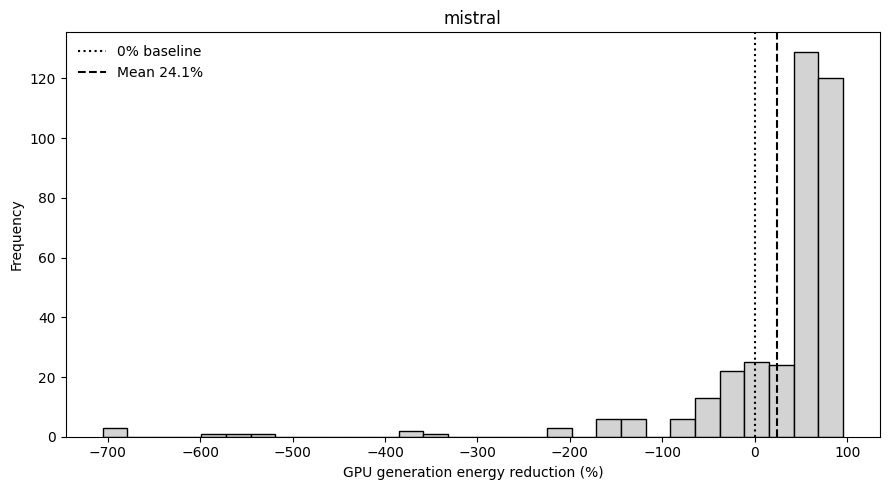

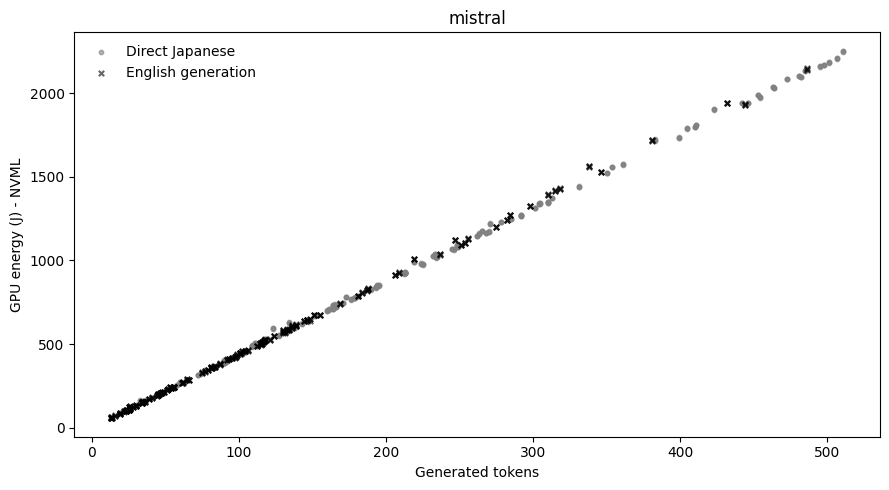

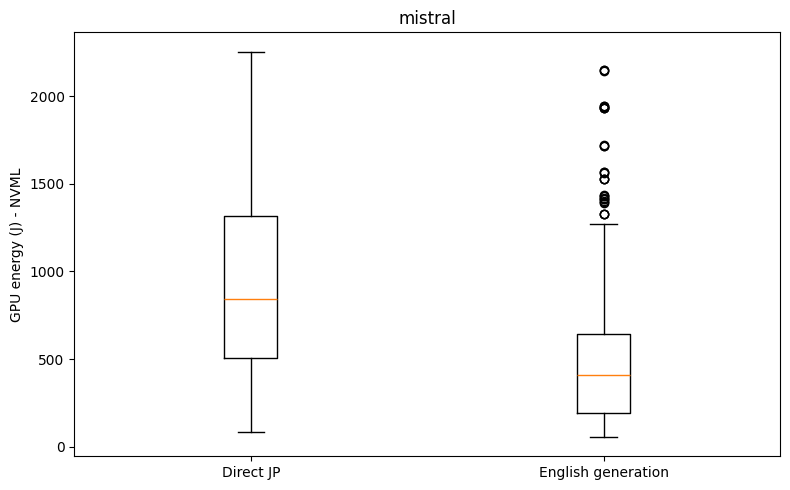

保存完了: mistral

グラフ生成: qwen (546ペア)


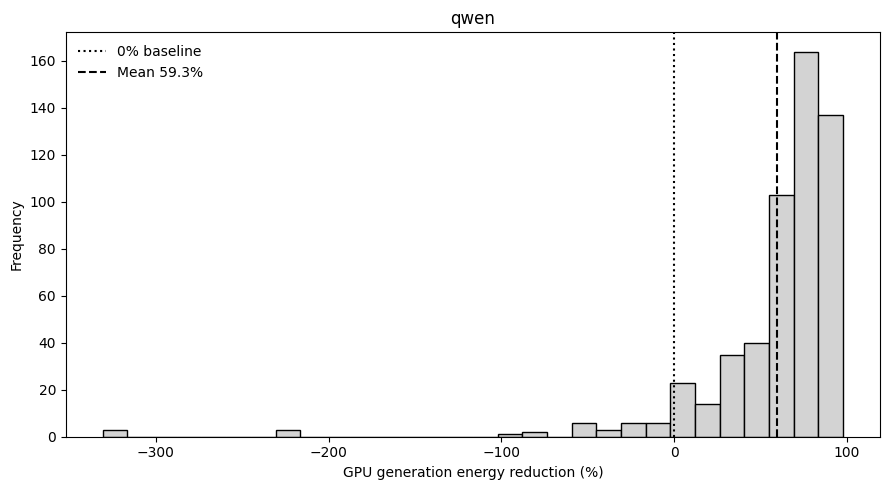

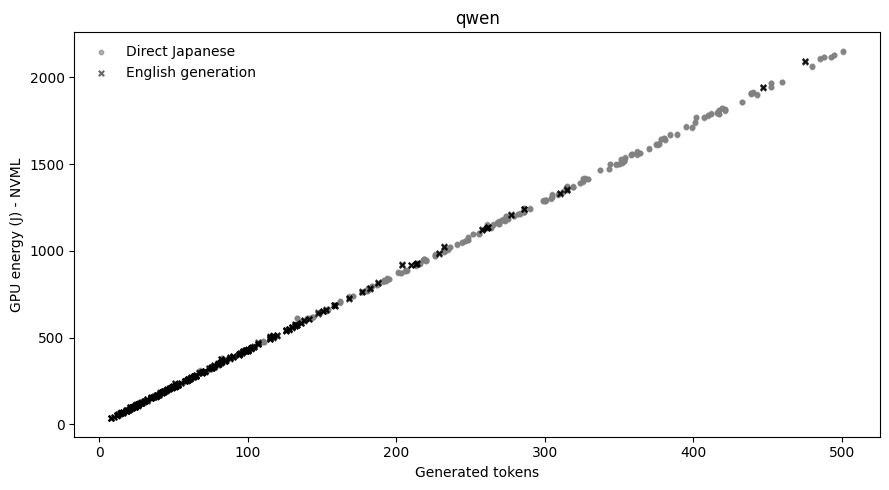

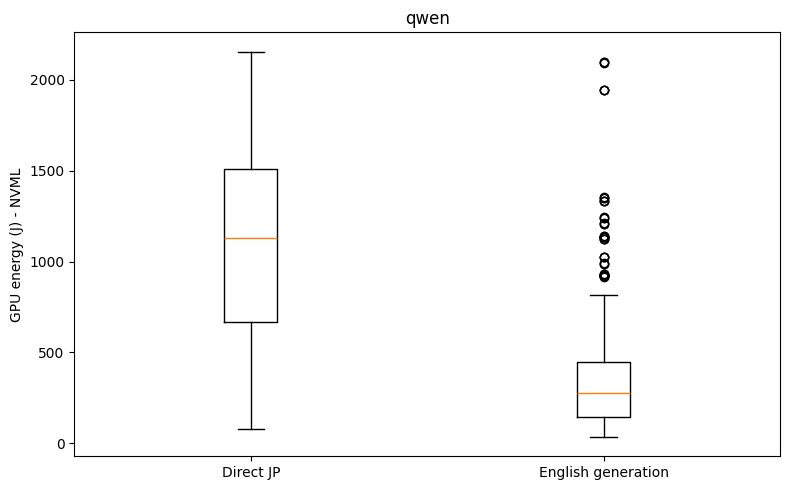

保存完了: qwen

全モデルのグラフ生成が完了しました


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# モデル別に独立して3種類のグラフを保存
if "pair" not in globals() or pair.empty:
    print("ペア比較データがありません")
else:
    for model_key, model_pair in pair.groupby("model_key"):
        suffix = str(model_key).replace("/", "_")
        print(f"\nグラフ生成: {model_key} ({len(model_pair)}ペア)")

        # ① GPU削減率の分布
        vals = pd.to_numeric(
            model_pair["gpu_generation_reduction_pct"],
            errors="coerce"
        ).dropna().to_numpy()

        if len(vals) > 0:
            fig, ax = plt.subplots(figsize=(9, 5))
            ax.hist(
                vals,
                bins=30 if len(vals) >= 100 else 10,
                facecolor="lightgray",
                edgecolor="black"
            )
            ax.axvline(0, ls=":", color="black", label="0% baseline")
            ax.axvline(
                np.mean(vals), ls="--", color="black",
                label=f"Mean {np.mean(vals):.1f}%"
            )
            ax.set_title(model_key)
            ax.set_xlabel("GPU generation energy reduction (%)")
            ax.set_ylabel("Frequency")
            ax.legend(frameon=False)
            fig.tight_layout()
            fig.savefig(
                RUN_DIR / f"gpu_generation_reduction_bw_{suffix}.png",
                dpi=300
            )
            plt.show()
            plt.close(fig)

        # ② 出力トークン数とGPUエネルギー
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.scatter(
            model_pair["output_tokens_jp"],
            model_pair["gpu_energy_j_jp"],
            s=10, marker="o", c="gray", alpha=0.6,
            label="Direct Japanese"
        )
        ax.scatter(
            model_pair["output_tokens_en"],
            model_pair["gpu_energy_j_en"],
            s=15, marker="x", c="black", alpha=0.6,
            label="English generation"
        )
        ax.set_title(model_key)
        ax.set_xlabel("Generated tokens")
        ax.set_ylabel("GPU energy (J) - NVML")
        ax.legend(frameon=False)
        fig.tight_layout()
        fig.savefig(
            RUN_DIR / f"tokens_vs_gpu_energy_bw_{suffix}.png",
            dpi=300
        )
        plt.show()
        plt.close(fig)

        # ③ GPUエネルギーの箱ひげ図
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.boxplot(
            [
                model_pair["gpu_energy_j_jp"].dropna(),
                model_pair["gpu_energy_j_en"].dropna()
            ],
            showfliers=True
        )
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["Direct JP", "English generation"])
        ax.set_title(model_key)
        ax.set_ylabel("GPU energy (J) - NVML")
        fig.tight_layout()
        fig.savefig(
            RUN_DIR / f"gpu_energy_box_bw_{suffix}.png",
            dpi=300
        )
        plt.show()
        plt.close(fig)

        print(f"保存完了: {model_key}")

    print("\n全モデルのグラフ生成が完了しました")


In [ ]:
print("今回の保存先:", RUN_DIR.resolve())

今回の保存先: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e


In [ ]:

print("RUN_LABEL:", RUN_LABEL)
print("RUN_DIR:", RUN_DIR)

for filename in [
    "generations.jsonl",
    "eligibility.jsonl",
]:
    path = RUN_DIR / filename

    if path.exists():
        count = sum(
            1 for line in path.open(
                encoding="utf-8"
            ) if line.strip()
        )
        print(f"{filename}: {count}件")
    else:
        print(f"{filename}: 存在しません")


RUN_LABEL: revision_v3_full_qwen_mistral_no_argos_cache_retry
RUN_DIR: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e
generations.jsonl: 2400件
eligibility.jsonl: 1200件


In [ ]:

print("保存先:", RUN_DIR)

required_files = [
    "generations.jsonl",
    "eligibility.jsonl",
    "translations.jsonl",
    "english_language_audit.csv",
    "pair_eligibility_audit.csv",
    "exclusion_summary.csv",
    "generation_summary.csv",
    "paired_results.csv",
]

for filename in required_files:
    path = RUN_DIR / filename
    print(
        "✅" if path.exists() else "❌",
        filename
    )


保存先: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e
✅ generations.jsonl
✅ eligibility.jsonl
✅ translations.jsonl
✅ english_language_audit.csv
✅ pair_eligibility_audit.csv
✅ exclusion_summary.csv
✅ generation_summary.csv
✅ paired_results.csv


In [ ]:
# 完了判定：件数・キー重複・想定外キー・ステータスを全て検査
import json
from datetime import datetime, timezone
from collections import Counter

_gens = load_jsonl(GEN_LOG)
_elig = load_jsonl(RUN_DIR / "eligibility.jsonl")
_trans = load_jsonl(TRANS_LOG)

_expected_gen_keys = {
    (model, int(p["prompt_id"]), rep, language)
    for model in ACTIVE_MODELS for p in PROMPTS
    for rep in range(REPEAT_COUNT) for language in ("ja", "en")
}
_expected_elig_keys = {
    (model, int(p["prompt_id"]), rep)
    for model in ACTIVE_MODELS for p in PROMPTS
    for rep in range(REPEAT_COUNT)
}
_gen_keys = [gen_key(row) for row in _gens]
_elig_keys = [simple_key(row) for row in _elig]
_trans_keys = [tr_key(row) for row in _trans]
_gen_map = {gen_key(row): row for row in _gens}
_eligible = {simple_key(row) for row in _elig if row.get("status") == "eligible"}
_expected_tr_keys = {
    (model, pid, rep, translator)
    for model, pid, rep in _eligible
    if (model, pid, rep, "en") in _gen_map
       and _gen_map[(model, pid, rep, "en")].get("status") == "ok"
    for translator in ACTIVE_TRANSLATORS
}

# 全件の状態と論理的な整合性を確認。エラーが1行でも混在すると完了にならない。
_consistent_eligibility = all(
    e.get("status") != "eligible" or (
        _gen_map.get((*simple_key(e), "ja"), {}).get("status") == "ok"
        and _gen_map.get((*simple_key(e), "en"), {}).get("status") == "ok"
    ) for e in _elig
)
_done = all((
    len(_gen_keys) == len(_expected_gen_keys),
    set(_gen_keys) == _expected_gen_keys,
    len(_elig_keys) == len(_expected_elig_keys),
    set(_elig_keys) == _expected_elig_keys,
    len(_trans_keys) == len(_expected_tr_keys),
    set(_trans_keys) == _expected_tr_keys,
    all(row.get("status") in ("ok", "excluded") for row in _gens),
    all(row.get("status") in ("eligible", "excluded") for row in _elig),
    all(row.get("status") in ("ok", "excluded") for row in _trans),
    _consistent_eligibility,
))

_status = {
    "status": "completed_all_attempts" if _done else "incomplete",
    "attempts_complete_does_not_mean_all_successful": True,
    "experiment_type": MODE,
    "models": ACTIVE_MODELS,
    "translation_cache_policy": TRANSLATION_CACHE_POLICY,
    "expected_generation_rows": len(_expected_gen_keys),
    "actual_generation_rows": len(_gen_keys),
    "expected_eligibility_rows": len(_expected_elig_keys),
    "actual_eligibility_rows": len(_elig_keys),
    "expected_translation_rows": len(_expected_tr_keys),
    "actual_translation_rows": len(_trans_keys),
    "generation_status_counts": dict(Counter(r.get("status") for r in _gens)),
    "translation_status_counts": dict(Counter(r.get("status") for r in _trans)),
    "missing_generation_keys": len(_expected_gen_keys - set(_gen_keys)),
    "missing_eligibility_keys": len(_expected_elig_keys - set(_elig_keys)),
    "missing_translation_keys": len(_expected_tr_keys - set(_trans_keys)),
    "unexpected_generation_keys": len(set(_gen_keys) - _expected_gen_keys),
    "unexpected_eligibility_keys": len(set(_elig_keys) - _expected_elig_keys),
    "unexpected_translation_keys": len(set(_trans_keys) - _expected_tr_keys),
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
}
(RUN_DIR / "run_status.json").write_text(
    json.dumps(_status, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("\n実行結果:", _status["status"])
print("生成:", len(_gen_keys), "/", len(_expected_gen_keys))
print("適格性:", len(_elig_keys), "/", len(_expected_elig_keys))
print("翻訳:", len(_trans_keys), "/", len(_expected_tr_keys))
print("保存:", RUN_DIR / "run_status.json")
if not _done:
    raise RuntimeError(
        "全予定試行が未完了です。run_status.json と errors.jsonl を確認し、"
        "同じ設定・RUN_LABELでNotebookを再実行してください。"
    )



実行結果: completed_all_attempts
生成: 2400 / 2400
適格性: 1200 / 1200
翻訳: 2853 / 2853
保存: /content/drive/MyDrive/LLM_Energy_Experiment_v2/revision_v3_full_qwen_mistral_no_argos_cache_retry/full/NVIDIA_L4/3106f584069e/run_status.json
